In [2]:
import os
import joblib
import pandas as pd
import numpy as np

print("FlowCast - Traffic Volume Model Evaluation")
print("Libraries imported successfully!")

FlowCast - Traffic Volume Model Evaluation
Libraries imported successfully!


In [3]:
import os

model_dir = "../models"

print("Model folder exists:", os.path.exists(model_dir))

print("\nSaved model files:")
for filename in os.listdir(model_dir):
    print(filename)

Model folder exists: True

Saved model files:
accident_risk_60m_model.joblib
accident_risk_model.joblib
congestion_classifier.pkl
congestion_features.json
congestion_svm_baseline.pkl
traffic_volume_features.json
traffic_volume_lstm.keras
traffic_volume_lstm_scaler.pkl
traffic_volume_random_forest.pkl


In [4]:
import os
import joblib

model_path = "../models/traffic_volume_random_forest.pkl"

if os.path.exists(model_path):
    traffic_model = joblib.load(model_path)
    print("Traffic-volume model loaded successfully!")
    print("Model type:", type(traffic_model).__name__)
else:
    print("Model file not found. Please check the model path.")

C:\Users\pathi\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Traffic-volume model loaded successfully!
Model type: RandomForestRegressor


C:\Users\pathi\anaconda3\Lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [5]:
import json
import os

features_path = "../models/traffic_volume_features.json"

print("Model evaluation preparation")
print("Model loaded:", traffic_model is not None)
print("Feature file exists:", os.path.exists(features_path))

if os.path.exists(features_path):
    with open(features_path, "r") as f:
        features = json.load(f)
    print("Feature information loaded successfully.")
    print("Feature information type:", type(features).__name__)
    print("Feature information:", features)

Model evaluation preparation
Model loaded: True
Feature file exists: True
Feature information loaded successfully.
Feature information type: list
Feature information: ['traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'avg_speed_lag_1', 'avg_speed_lag_2', 'traffic_volume_rolling_mean_4', 'avg_speed_rolling_mean_4', 'hour', 'minute', 'day_of_week', 'month', 'is_weekend', 'is_morning_peak', 'is_evening_peak']


In [6]:
import pandas as pd
import os

print("Checking FlowCast data files...")

for folder in ["../data", "../models"]:
    print(f"\nFiles in {folder}:")
    if os.path.exists(folder):
        print(os.listdir(folder))
    else:
        print("Folder not found")

Checking FlowCast data files...

Files in ../data:
['calendar_events.csv', 'flowcast_congestion_cleaned.csv', 'flowcast_merged_cleaned.csv', 'flowcast_traffic_cleaned.csv', 'processed', 'traffic_sensor_log.csv', 'uploaded_traffic_data.csv', 'weather_observations.csv']

Files in ../models:
['accident_risk_60m_model.joblib', 'accident_risk_model.joblib', 'congestion_classifier.pkl', 'congestion_features.json', 'congestion_svm_baseline.pkl', 'traffic_volume_features.json', 'traffic_volume_lstm.keras', 'traffic_volume_lstm_scaler.pkl', 'traffic_volume_random_forest.pkl']


In [7]:
import os

processed_path = "../data/processed"

print("Processed folder exists:", os.path.exists(processed_path))

if os.path.exists(processed_path):
    print("\nFiles in processed folder:")
    for filename in os.listdir(processed_path):
        print(filename)

Processed folder exists: True

Files in processed folder:
calendar_cleaned.csv
data_quality_report.csv
flowcast_features.csv
flowcast_merged.csv
traffic_cleaned.csv
weather_cleaned.csv


In [8]:
import pandas as pd

data_path = "../data/processed/flowcast_features.csv"

df_eval = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df_eval.shape)

print("\nColumn names:")
print(df_eval.columns.tolist())

print("\nFirst 5 rows:")
display(df_eval.head())

Dataset loaded successfully!
Dataset shape: (176701, 46)

Column names:
['road_id', 'road_name', 'latitude', 'longitude', 'weather_station_id', 'date', 'time', 'traffic_volume', 'vehicle_count', 'vehicle_type_dist', 'avg_speed', 'occupancy', 'congestion_level', 'travel_time', 'accident_count', 'signal_timing', 'road_capacity', 'timestamp', 'capacity_30min', 'volume_capacity_ratio', 'date_weather', 'time_weather', 'weather_condition', 'temperature', 'rainfall', 'visibility', 'public_holiday', 'holiday_name', 'event_flag', 'event_name', 'roadwork_flag', 'hour', 'minute', 'day_of_week', 'day_of_month', 'month', 'is_weekend', 'is_morning_peak', 'is_evening_peak', 'traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'avg_speed_lag_1', 'avg_speed_lag_2', 'traffic_volume_rolling_mean_4', 'avg_speed_rolling_mean_4']

First 5 rows:


,road_id,road_name,latitude,longitude,weather_station_id,date,time,traffic_volume,vehicle_count,vehicle_type_dist,...,is_weekend,is_morning_peak,is_evening_peak,traffic_volume_lag_1,traffic_volume_lag_2,traffic_volume_lag_4,avg_speed_lag_1,avg_speed_lag_2,traffic_volume_rolling_mean_4,avg_speed_rolling_mean_4
0,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,00:00,97.0,97,"{""2W"": 0.39, ""Car"": 0.35, ""LCV"": 0.12, ""HCV"": ...",...,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,00:30,99.0,99,"{""2W"": 0.44, ""Car"": 0.34, ""LCV"": 0.11, ""HCV"": ...",...,0,0,0,97.0,NaN,NaN,53.0,NaN,NaN,NaN
2,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,01:00,102.0,102,"{""2W"": 0.44, ""Car"": 0.43, ""LCV"": 0.06, ""HCV"": ...",...,0,0,0,99.0,97.0,NaN,56.7,53.0,98.000000,54.850000
3,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,01:30,113.0,113,"{""2W"": 0.43, ""Car"": 0.36, ""LCV"": 0.09, ""HCV"": ...",...,0,0,0,102.0,99.0,NaN,55.7,56.7,99.333333,55.133333
4,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,02:00,92.0,92,"{""2W"": 0.42, ""Car"": 0.39, ""LCV"": 0.09, ""HCV"": ...",...,0,0,0,113.0,102.0,97.0,53.5,55.7,102.750000,54.725000


In [9]:
# Check the model's expected features
print("Dataset rows:", len(df_eval))
print("Dataset columns:", len(df_eval.columns))

print("\nModel expected features:")
if hasattr(traffic_model, "feature_names_in_"):
    model_features = list(traffic_model.feature_names_in_)
    print(model_features)
else:
    model_features = features
    print(model_features)

print("\nFeatures missing from dataset:")
print([col for col in model_features if col not in df_eval.columns])

print("\nNumber of model features:", len(model_features))

Dataset rows: 176701
Dataset columns: 46

Model expected features:
['traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'avg_speed_lag_1', 'avg_speed_lag_2', 'traffic_volume_rolling_mean_4', 'avg_speed_rolling_mean_4', 'hour', 'minute', 'day_of_week', 'month', 'is_weekend', 'is_morning_peak', 'is_evening_peak']

Features missing from dataset:
[]

Number of model features: 14


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Prepare model inputs
X = df_eval[model_features].copy()

# Check the target column
print("Available target columns:")
print([col for col in df_eval.columns
       if "traffic_volume" in col.lower()])

Available target columns:
['traffic_volume', 'traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'traffic_volume_rolling_mean_4']


In [11]:
# Check whether the model features include the actual target
print("Target column:", "traffic_volume")
print("Target included in model features:",
      "traffic_volume" in model_features)

# Prepare input features
X = df_eval[model_features].copy()

# Check input data
print("Evaluation rows:", len(X))
print("Missing values in inputs:", X.isnull().sum().sum())
print("Input shape:", X.shape)

Target column: traffic_volume
Target included in model features: False
Evaluation rows: 176701
Missing values in inputs: 350
Input shape: (176701, 14)


In [12]:
# Check missing values in each feature
missing_counts = X.isnull().sum()

print("Missing values by feature:")
print(missing_counts[missing_counts > 0])

# Fill missing values using each feature's median
X = X.fillna(X.median(numeric_only=True))

print("\nMissing values remaining:", X.isnull().sum().sum())
print("Input shape after cleaning:", X.shape)

Missing values by feature:
traffic_volume_lag_1              25
traffic_volume_lag_2              50
traffic_volume_lag_4             100
avg_speed_lag_1                   25
avg_speed_lag_2                   50
traffic_volume_rolling_mean_4     50
avg_speed_rolling_mean_4          50
dtype: int64

Missing values remaining: 0
Input shape after cleaning: (176701, 14)


In [13]:
# Check actual traffic-volume target values
print("Target column exists:",
      "traffic_volume" in df_eval.columns)

y_true = df_eval["traffic_volume"].copy()

print("\nTarget missing values:", y_true.isnull().sum())
print("Minimum traffic volume:", y_true.min())
print("Maximum traffic volume:", y_true.max())
print("Average traffic volume:", y_true.mean())
print("\nFirst 5 actual values:")
print(y_true.head())

Target column exists: True

Target missing values: 0
Minimum traffic volume: 41.0
Maximum traffic volume: 2090.0
Average traffic volume: 431.43658213592454

First 5 actual values:
0     97.0
1     99.0
2    102.0
3    113.0
4     92.0
Name: traffic_volume, dtype: float64


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Generate predictions using the saved Random Forest model
y_pred = traffic_model.predict(X)

# Calculate evaluation metrics
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

# Avoid division by zero when calculating MAPE
nonzero = y_true != 0
mape = np.mean(
    np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])
) * 100

print("Traffic Volume Model Evaluation")
print("--------------------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

Traffic Volume Model Evaluation
--------------------------------
MAE:  22.96
RMSE: 37.51
MAPE: 5.67%


In [15]:
import os
import pandas as pd

os.makedirs("../reports", exist_ok=True)

evaluation_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE"],
    "Value": [mae, rmse, mape]
})

evaluation_results.to_csv(
    "../reports/traffic_volume_evaluation.csv",
    index=False
)

print(evaluation_results)
print("\nEvaluation results saved successfully!")
print("Location: reports/traffic_volume_evaluation.csv")

  Metric      Value
0    MAE  22.956750
1   RMSE  37.511078
2   MAPE   5.671532

Evaluation results saved successfully!
Location: reports/traffic_volume_evaluation.csv


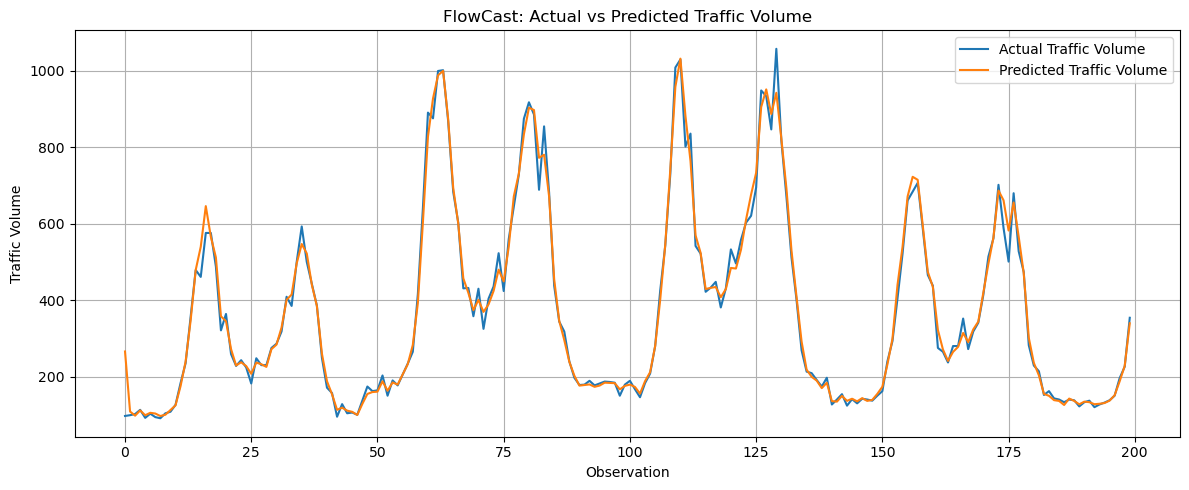

In [16]:
import matplotlib.pyplot as plt

# Compare a sample of 200 observations
sample_size = min(200, len(y_true))

plt.figure(figsize=(12, 5))

plt.plot(
    range(sample_size),
    y_true.iloc[:sample_size].to_numpy(),
    label="Actual Traffic Volume"
)

plt.plot(
    range(sample_size),
    y_pred[:sample_size],
    label="Predicted Traffic Volume"
)

plt.title("FlowCast: Actual vs Predicted Traffic Volume")
plt.xlabel("Observation")
plt.ylabel("Traffic Volume")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
import os

os.makedirs("../reports", exist_ok=True)

plt.savefig(
    "../reports/traffic_volume_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

print("Graph saved successfully!")

Graph saved successfully!


<Figure size 640x480 with 0 Axes>

In [18]:
# Compare actual and predicted traffic volumes

comparison = pd.DataFrame({
    "Actual_Traffic_Volume": y_true.iloc[:10].values,
    "Predicted_Traffic_Volume": y_pred[:10]
})

comparison["Absolute_Error"] = abs(
    comparison["Actual_Traffic_Volume"]
    - comparison["Predicted_Traffic_Volume"]
)

print("First 10 actual vs predicted values:")
display(comparison.round(2))

First 10 actual vs predicted values:


,Actual_Traffic_Volume,Predicted_Traffic_Volume,Absolute_Error
0,97.0,265.76,168.76
1,99.0,108.58,9.58
2,102.0,97.79,4.21
3,113.0,111.46,1.54
4,92.0,98.87,6.87
5,103.0,105.25,2.25
6,94.0,103.36,9.36
7,91.0,96.84,5.84
8,104.0,100.25,3.75
9,108.0,112.35,4.35


In [19]:
# Analyze prediction errors across the full dataset

errors = np.abs(np.asarray(y_true) - np.asarray(y_pred))

print("Total predictions:", len(errors))
print("Mean absolute error:", round(errors.mean(), 2))
print("Median absolute error:", round(np.median(errors), 2))
print("Maximum absolute error:", round(errors.max(), 2))
print("Predictions with error above 100:",
      int((errors > 100).sum()))

print("\nLargest 10 prediction errors:")
largest_errors = pd.DataFrame({
    "Actual": np.asarray(y_true),
    "Predicted": np.asarray(y_pred),
    "Absolute_Error": errors
})

display(
    largest_errors
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

Total predictions: 176701
Mean absolute error: 22.96
Median absolute error: 12.84
Maximum absolute error: 455.8
Predictions with error above 100: 5108

Largest 10 prediction errors:


,Actual,Predicted,Absolute_Error
98321,1078.0,622.20,455.80
98605,905.0,1313.96,408.96
34911,770.0,1175.87,405.87
160675,1344.0,939.93,404.07
106634,1829.0,1425.03,403.97
27887,1324.0,920.09,403.91
41961,1096.0,1499.35,403.35
119737,1253.0,854.01,398.99
98578,1050.0,1428.64,378.64
34908,1640.0,1262.06,377.94


In [20]:
# Compare prediction errors for low, medium, and high traffic

error_analysis = largest_errors.copy()

error_analysis["Traffic_Level"] = pd.cut(
    error_analysis["Actual"],
    bins=[-float("inf"), 200, 500, float("inf")],
    labels=["Low traffic", "Medium traffic", "High traffic"]
)

summary = error_analysis.groupby(
    "Traffic_Level", observed=False
).agg(
    Number_of_Rows=("Absolute_Error", "size"),
    Mean_Absolute_Error=("Absolute_Error", "mean"),
    Maximum_Error=("Absolute_Error", "max")
).round(2)

display(summary)

,Number_of_Rows,Mean_Absolute_Error,Maximum_Error
Traffic_Level,,,
Low traffic,46200,9.00,202.76
Medium traffic,69877,18.61,316.79
High traffic,60624,38.60,455.80


In [21]:
# Save traffic-level error analysis

summary.to_csv(
    "../reports/traffic_volume_error_by_level.csv"
)

print("Traffic-level error analysis saved successfully!")
print("Location: reports/traffic_volume_error_by_level.csv")

Traffic-level error analysis saved successfully!
Location: reports/traffic_volume_error_by_level.csv


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Prepare data
X = df_eval[model_features].copy()
y = df_eval["traffic_volume"].copy()

# Keep only rows with valid target values
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

# Chronological 80/20 split
split = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Models to compare
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=15, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=50, random_state=42
    )
}

results = []

for name, model in models.items():
    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        model
    )

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mape = np.mean(
        np.abs((y_test - predictions) / y_test.clip(lower=1))
    ) * 100

    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "MAPE": round(mape, 2)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df.sort_values("RMSE"))

,Model,MAE,RMSE,MAPE
2,Random Forest,39.82,58.74,10.34
1,Decision Tree,46.23,70.04,11.83
3,Gradient Boosting,48.54,70.18,13.49
0,Linear Regression,60.10,81.65,18.05


In [23]:
# TRAFFIC VOLUME PREDICTION CONFIDENCE INTERVAL
import numpy as np
import pandas as pd

# Use existing test predictions and actual values
errors = np.abs(np.array(y_test) - np.array(predictions))

# Calculate 90% error range from validation errors
error_margin = np.percentile(errors, 90)

confidence_results = pd.DataFrame({
    "Actual": np.array(y_test),
    "Predicted": np.array(predictions)
})

confidence_results["Lower_Bound"] = (
    confidence_results["Predicted"] - error_margin
).clip(lower=0)

confidence_results["Upper_Bound"] = (
    confidence_results["Predicted"] + error_margin
)

print("90% prediction interval created")
print("Error margin:", round(error_margin, 2))
display(confidence_results.head(10))

90% prediction interval created
Error margin: 115.28


,Actual,Predicted,Lower_Bound,Upper_Bound
0,418.0,416.729960,301.450473,532.009448
1,576.0,514.368333,399.088845,629.647821
2,670.0,654.970692,539.691205,770.250180
3,578.5,628.348282,513.068795,743.627770
4,487.0,569.473885,454.194397,684.753372
5,398.0,462.807560,347.528072,578.087048
6,410.0,395.945112,280.665624,511.224600
7,253.0,392.920337,277.640849,508.199824
8,224.0,246.550171,131.270684,361.829659
9,203.0,229.897897,114.618409,345.177384


In [24]:
comparison_df.to_csv(
    "../reports/regression_model_scoreboard.csv",
    index=False
)

print("Regression scoreboard saved successfully!")

Regression scoreboard saved successfully!


In [25]:
import importlib.util

print("XGBoost installed:",
      importlib.util.find_spec("xgboost") is not None)

XGBoost installed: False


In [26]:
%pip install xgboost


   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -- ------------------------------------- 3.4/48.9 MB 20.2 MB/s eta 0:00:03
   ----- ---------------------------------- 6.3/48.9 MB 16.0 MB/s eta 0:00:03
   ------- -------------------------------- 8.9/48.9 MB 14.9 MB/s eta 0:00:03
   --------- ------------------------------ 11.3/48.9 MB 14.2 MB/s eta 0:00:03
   ----------- ---------------------------- 14.2/48.9 MB 14.1 MB/s eta 0:00:03
   ------------- -------------------------- 16.0/48.9 MB 13.3 MB/s eta 0:00:03
   --------------- ------------------------ 18.9/48.9 MB 13.3 MB/s eta 0:00:03
   ----------------- ---------------------- 21.8/48.9 MB 13.4 MB/s eta 0:00:03
   -------------------- ------------------- 24.6/48.9 MB 13.5 MB/s eta 0:00:02
   ---------------------- ----------------- 27.0/48.9 MB 13.1 MB/s eta 0:00:02
   ----------------------- ---------------- 29.4/48.9 MB 13.0 MB/s eta 0:00:02
   -------------------------- ------------- 32.2/48.9 MB 13.1 M


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("XGBoost installed successfully!")

XGBoost version: 3.4.1
XGBoost installed successfully!


In [29]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Train XGBoost
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

# Predictions
xgb_predictions = xgb_model.predict(X_test)

# Evaluation
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_mape = np.mean(
    np.abs((y_test - xgb_predictions) / y_test.clip(lower=1))
) * 100

print("XGBoost MAE:", round(xgb_mae, 2))
print("XGBoost RMSE:", round(xgb_rmse, 2))
print("XGBoost MAPE:", round(xgb_mape, 2))

XGBoost MAE: 40.04
XGBoost RMSE: 58.54
XGBoost MAPE: 10.58


In [30]:
xgb_result = pd.DataFrame([{
    "Model": "XGBoost",
    "MAE": round(xgb_mae, 2),
    "RMSE": round(xgb_rmse, 2),
    "MAPE": round(xgb_mape, 2)
}])

comparison_df = pd.concat(
    [comparison_df, xgb_result],
    ignore_index=True
)

comparison_df = comparison_df.sort_values("RMSE")

display(comparison_df)

comparison_df.to_csv(
    "../reports/regression_model_scoreboard.csv",
    index=False
)

print("Updated regression scoreboard saved!")

,Model,MAE,RMSE,MAPE
4,XGBoost,40.04,58.54,10.58
2,Random Forest,39.82,58.74,10.34
1,Decision Tree,46.23,70.04,11.83
3,Gradient Boosting,48.54,70.18,13.49
0,Linear Regression,60.10,81.65,18.05


Updated regression scoreboard saved!


In [31]:
import joblib

joblib.dump(
    xgb_model,
    "../models/traffic_volume_xgboost.pkl"
)

print("XGBoost model saved successfully!")

XGBoost model saved successfully!
